# PhageLysData EDA manuscript panel — publication layout refined (v9)

Rebuilds the original EDA figure using the **same frozen E0–E6 files**, panel data, colors, representations, and plot design as v6. Only the figure layout and text/axes sizes are adjusted to the supplied final mockup.

Layout:

- Top row: **A** annotation/core composition · **D** physicochemical effect heatmap · **F** ESM2-T30 primary-group t-SNE.
- Middle: **B** two length distributions · **E** three physicochemical distributions · **F** ESM2-T30 subtype t-SNE over **G** same-subtype neighborhood bar chart.
- Bottom: **C** complete 20-amino-acid composition-effect heatmap across all three columns.

**G now consists only of the bar chart.** The earlier silhouette-curve subpanel is intentionally omitted, as in the revised layout. No source values are recomputed or changed.

Run from the project root or `EDA/` directory with access to the original `EDA_results/` hierarchy. Saves a vector PDF and a high-resolution PNG under `EDA_results/E_panel/`.

Layout refinements from the v7 manuscript preview: figure width fixed at 16.6 inches, slightly taller canvas, tighter horizontal spacing, left-aligned subtype t-SNE within its allocated column, colorbar label rotated out of the heatmap, and length-distribution subtitles placed above their axes (not over the KDEs). All source data, values and palettes remain unchanged.

**v9 layout correction:** Only the two F t-SNE scatter plots are broadened and right-aligned in their allotted column to use previously empty space and avoid crowding near the D heatmap/colorbar. G is unchanged. Figure width remains 16.6 inches and height 15.1 inches; original sources, colors, data and analysis remain unchanged.


In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec, GridSpecFromSubplotSpec
from matplotlib.lines import Line2D

warnings.filterwarnings("ignore")

# ------------------------------------------------------------------
# Style
# ------------------------------------------------------------------
sns.set_theme(
    context="paper",
    style="white",
    font="DejaVu Sans",
    rc={
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.linewidth": 0.8,
        "axes.edgecolor": "#7F93A8",
        "xtick.color": "#3F5061",
        "ytick.color": "#3F5061",
        "axes.labelcolor": "#31465A",
        "text.color": "#31465A",
        "figure.facecolor": "white",
        "axes.facecolor": "white",
    },
)

# Enlarged editorial typography while preserving the v6 colors and seaborn theme.
mpl.rcParams.update({
    "font.size": 13.0,
    "axes.labelsize": 12.3,
    "axes.titlesize": 13.0,
    "xtick.labelsize": 10.8,
    "ytick.labelsize": 10.8,
    "legend.fontsize": 10.2,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

COLORS = {
    "P_core": "#4F81BD",
    "P core": "#4F81BD",
    "N_easy": "#9BB7D3",
    "N_hard": "#5FA8A0",
    "Unknown": "#B8B8D6",
    "Negative": "#8EABC8",
    "Endolysin": "#4F81BD",
    "DPO": "#7E9FC7",
    "VAL": "#65B5A6",
    "E2 composition": "#8FB1D5",
    "E3 physicochemical": "#72B7B2",
    "E2+E3 combined": "#507FB4",
    "ESM2-T6": "#A89CC8",
    "ESM2-T30": "#6F5FA8",
}

DIVERGING_CMAP = sns.diverging_palette(245, 15, s=70, l=65, center="light", as_cmap=True)
LETTER_COLOR = "#315A84"

DISPLAY_NAMES = {
    "P_core": "P core",
    "N_easy": "N easy",
    "N_hard": "N hard",
    "N_mixed": "N mixed",
    "Unknown": "Unknown",
    "Negative": "Negative",
}

# ------------------------------------------------------------------
# Project-root and frozen-output discovery
# ------------------------------------------------------------------
def discover_project_root() -> Path:
    cwd = Path.cwd().resolve()

    # Preserve the layout used by the original EDA notebook when run
    # from a directory named EDA.
    preferred = cwd.parent if cwd.name.lower() == "eda" else cwd

    candidates = []
    for p in [preferred, cwd, *cwd.parents]:
        if p not in candidates:
            candidates.append(p)

    for root in candidates:
        if (root / "EDA_results").is_dir():
            return root

    raise FileNotFoundError(
        "Could not locate the PhageLysData project root. Run this notebook "
        "from the project directory (or a subdirectory) containing EDA_results/."
    )

PROJECT_ROOT = discover_project_root()
EDA_ROOT = PROJECT_ROOT / "EDA_results"
OUTPUT_DIR = EDA_ROOT / "E_panel"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

FILE_LOCATIONS = {
    "phagelytic_eda_universe.csv": "E0",
    "dataset_composition.tsv": "E1",
    "length_summary.tsv": "E1",
    "aac_effects_global.tsv": "E2",
    "global_descriptor_effects.tsv": "E3",
    "descriptor_rankings.tsv": "E3",
    "descriptor_statistics.tsv": "E3",
    "physicochemical_descriptors.parquet": "E3",
    "embedding_esm2_t30_tsne_global.tsv": "E5_v2",
    "embedding_esm2_t30_tsne_subtypes.tsv": "E5_v2",
    "subtype_consistency.tsv": "E6",
}

def find_file(filename: str) -> Path:
    if filename in FILE_LOCATIONS:
        expected = EDA_ROOT / FILE_LOCATIONS[filename] / filename
        if expected.is_file():
            return expected

    # Safe fallback inside the already identified EDA tree only.
    matches = list(EDA_ROOT.rglob(filename))
    if len(matches) == 1:
        return matches[0]
    if len(matches) > 1:
        raise FileNotFoundError(
            f"Multiple copies of {filename!r} found under {EDA_ROOT}; "
            "please keep the frozen EDA output hierarchy unambiguous."
        )
    raise FileNotFoundError(f"Could not locate required frozen output: {filename}")

print("Project root:", PROJECT_ROOT)
print("EDA root    :", EDA_ROOT)
print("Output dir  :", OUTPUT_DIR)


Project root: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass
EDA root    : /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results
Output dir  : /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E_panel


In [2]:
# ------------------------------------------------------------------
# Load the frozen E0–E6 outputs used by the figure
# ------------------------------------------------------------------
dataset_composition = pd.read_csv(find_file("dataset_composition.tsv"), sep="\t")

# E0 is used only for group membership and sequence IDs.
eda_universe = pd.read_csv(
    find_file("phagelytic_eda_universe.csv"),
    usecols=["sequence_uid", "sequence_length", "phage_lytic", "clean_subtype", "P_core", "N_easy", "N_hard"],
)

aac_effects_global = pd.read_csv(find_file("aac_effects_global.tsv"), sep="\t")
global_descriptor_effects = pd.read_csv(find_file("global_descriptor_effects.tsv"), sep="\t")
descriptor_rankings = pd.read_csv(find_file("descriptor_rankings.tsv"), sep="\t")
descriptor_statistics = pd.read_csv(find_file("descriptor_statistics.tsv"), sep="\t")

t30_tsne_global = pd.read_csv(find_file("embedding_esm2_t30_tsne_global.tsv"), sep="\t")
t30_tsne_subtypes = pd.read_csv(find_file("embedding_esm2_t30_tsne_subtypes.tsv"), sep="\t")

subtype_consistency = pd.read_csv(find_file("subtype_consistency.tsv"), sep="\t")

print("Loaded frozen E0, E1, E2, E3, E5_v2 and E6 outputs.")


Loaded frozen E0, E1, E2, E3, E5_v2 and E6 outputs.


In [3]:
# ------------------------------------------------------------------
# Prepare panel data
# ------------------------------------------------------------------

# ================================================================
# A — percentage composition
# ================================================================
primary_comp = (
    dataset_composition
    .query("section == 'phage_lytic'")
    .set_index("label")
    .loc[["yes", "no", "unknown"]]
    .reset_index()
)
primary_comp["display"] = ["P core", "Negative", "Unknown"]
primary_comp["percent"] = primary_comp["fraction"] * 100

core_subtypes = dataset_composition.query("section == 'core_subtype'").copy()
subtype_comp = pd.DataFrame({
    "display": ["Endolysin", "DPO", "VAL"],
    "count": [
        int(core_subtypes.loc[core_subtypes["label"].eq("endolysin"), "count"].iloc[0]),
        int(core_subtypes.loc[core_subtypes["label"].eq("depolymerase"), "count"].iloc[0]),
        int(core_subtypes.loc[core_subtypes["label"].eq("virion_associated_lytic_enzyme"), "count"].iloc[0]),
    ],
})
subtype_comp["percent"] = subtype_comp["count"] / subtype_comp["count"].sum() * 100

# ================================================================
# B — full length distributions
# ================================================================
length_global = eda_universe.loc[:, ["sequence_length", "phage_lytic", "P_core", "N_easy", "N_hard"]].copy()
length_global["group"] = np.select(
    [
        length_global["P_core"].eq(True),
        length_global["N_easy"].eq(True),
        length_global["N_hard"].eq(True),
        length_global["phage_lytic"].eq("unknown"),
    ],
    ["P_core", "N_easy", "N_hard", "Unknown"],
    default="Other",
)
length_global = length_global.loc[
    length_global["group"].isin(["P_core", "N_easy", "N_hard", "Unknown"]),
    ["sequence_length", "group"],
].copy()

length_subtypes = eda_universe.loc[
    eda_universe["clean_subtype"].isin([
        "endolysin",
        "depolymerase",
        "virion_associated_lytic_enzyme",
    ]),
    ["sequence_length", "clean_subtype"],
].copy()
length_subtypes["group"] = length_subtypes["clean_subtype"].map({
    "endolysin": "Endolysin",
    "depolymerase": "DPO",
    "virion_associated_lytic_enzyme": "VAL",
})

# ================================================================
# C — all 20 amino-acid composition effects
# ================================================================
AAC_ORDER = list("ACDEFGHIKLMNPQRSTVWY")
contrast_map = {
    "P_core_vs_N_easy": "P core vs N easy",
    "P_core_vs_N_hard": "P core vs N hard",
    "P_core_vs_N_mixed": "P core vs N mixed",
}
contrast_order = ["P core vs N easy", "P core vs N hard", "P core vs N mixed"]

aac_df = aac_effects_global.loc[
    aac_effects_global["feature"].str.startswith("aac_freq_")
    & aac_effects_global["contrast"].isin(contrast_map)
].copy()
aac_df["aa"] = aac_df["feature"].str.replace("aac_freq_", "", regex=False)
aac_df["contrast_short"] = aac_df["contrast"].map(contrast_map)
aac_matrix = (
    aac_df
    .pivot(index="contrast_short", columns="aa", values="cliffs_delta")
    .reindex(index=contrast_order, columns=AAC_ORDER)
)

# ================================================================
# D — top non-length physicochemical descriptors
# ================================================================
ranked_desc = (
    descriptor_rankings
    .query("scope == 'global_target_vs_background' and primary_ranking_eligible == True")
    .sort_values("rank_primary_non_length_proxy")
)
top_features = ranked_desc["feature"].dropna().head(8).tolist()

def short_descriptor(name):
    lookup = {
        "structural_propensity_helix_mean": "helix",
        "global_basic_hydropathy_std": "hydropathy SD",
        "order_disorder_flexibility_fraction": "flexibility",
        "aaindex_FAUJ880104_mean": "AAindex FAUJ",
        "global_basic_charged_fraction": "charged frac.",
        "global_basic_fcr": "FCR",
        "global_basic_polarity_mean": "polarity",
        "global_basic_polarity_std": "polarity SD",
    }
    return lookup.get(name, name.replace("global_basic_", "").replace("_", " "))

desc_df = global_descriptor_effects.loc[
    global_descriptor_effects["contrast"].isin(contrast_map)
    & global_descriptor_effects["feature"].isin(top_features)
].copy()
desc_df["contrast_short"] = desc_df["contrast"].map(contrast_map)
desc_df["feature_short"] = desc_df["feature"].map(short_descriptor)
desc_order = [short_descriptor(x) for x in top_features]
desc_matrix = (
    desc_df
    .pivot(index="contrast_short", columns="feature_short", values="cliffs_delta")
    .reindex(index=contrast_order, columns=desc_order)
)

# ================================================================
# E — selected high-priority descriptor distributions
# ================================================================
# These three are deliberately selected from the ranked descriptors in D:
# one structural, one hydropathy-related, and one charge/composition-related.
preferred_properties = [
    "structural_propensity_helix_mean",
    "order_disorder_flexibility_fraction",
    "global_basic_charged_fraction",
]
selected_properties = [f for f in preferred_properties if f in top_features]
if len(selected_properties) < 3:
    selected_properties += [f for f in top_features if f not in selected_properties][:3-len(selected_properties)]

PROPERTY_LABELS = {
    "structural_propensity_helix_mean": "Helix propensity",
    "global_basic_hydropathy_std": "Hydropathy SD",
    "global_basic_charged_fraction": "Charged fraction",
    "order_disorder_flexibility_fraction": "Flexibility fraction",
    "aaindex_FAUJ880104_mean": "AAIndex FAUJ880104",
    "global_basic_fcr": "FCR",
    "global_basic_polarity_mean": "Mean polarity",
    "global_basic_polarity_std": "Polarity SD",
}

property_mode = "summary"
property_raw = None
parquet_path = find_file("physicochemical_descriptors.parquet")

# Use the original E3 descriptor values whenever a parquet backend is available.
# If the local environment lacks one, the notebook falls back to the frozen E3
# quantile summaries rather than failing.
try:
    property_raw = pd.read_parquet(
        parquet_path,
        columns=["sequence_uid", *selected_properties],
    )
    property_mode = "raw"
except Exception:
    try:
        import polars as pl
        pl_df = pl.read_parquet(
            parquet_path,
            columns=["sequence_uid", *selected_properties],
        )
        property_raw = pd.DataFrame(pl_df.to_dict(as_series=False))
        property_mode = "raw"
    except Exception:
        property_mode = "summary"

if property_mode == "raw":
    membership = eda_universe[["sequence_uid", "P_core", "N_easy", "N_hard"]].copy()
    property_raw = property_raw.merge(membership, on="sequence_uid", how="inner")
    raw_groups = []
    for group in ["P_core", "N_easy", "N_hard"]:
        temp = property_raw.loc[property_raw[group].astype(bool), ["sequence_uid", *selected_properties]].copy()
        temp["group"] = group
        raw_groups.append(temp)
    property_raw = pd.concat(raw_groups, ignore_index=True)
else:
    property_summary = descriptor_statistics.loc[
        descriptor_statistics["section"].eq("primary_state")
        & descriptor_statistics["group"].isin(["P_core", "N_easy", "N_hard"])
        & descriptor_statistics["feature"].isin(selected_properties)
    ].copy()

print("Panel E descriptor mode:", property_mode)
print("Selected properties:", [PROPERTY_LABELS.get(x, x) for x in selected_properties])

# ================================================================
# F — ESM2-T30 t-SNE only
# ================================================================
e5_global = t30_tsne_global.loc[
    t30_tsne_global["sequence_state"].isin(["P_core", "N_easy", "N_hard"])
].copy()
e5_subtypes = t30_tsne_subtypes.loc[
    t30_tsne_subtypes["subtype_label"].isin([
        "endolysin",
        "depolymerase",
        "virion_associated_lytic_enzyme",
    ])
].copy()

# ================================================================
# G — same-subtype neighborhood consistency
# ================================================================
rep_order = [
    "E2 composition",
    "E3 physicochemical",
    "E2+E3 combined",
    "ESM2-T6",
    "ESM2-T30",
]

subtype_knn = subtype_consistency.loc[
    subtype_consistency["metric"].eq("same_subtype_knn_fraction")
    & subtype_consistency["display_name"].isin(rep_order)
].copy()
subtype_knn_rep = (
    subtype_knn
    .groupby("display_name", as_index=False)["value"]
    .mean()
    .set_index("display_name")
    .reindex(rep_order)
    .reset_index()
)

HEATMAP_LIM = max(
    float(np.nanmax(np.abs(aac_matrix.to_numpy()))),
    float(np.nanmax(np.abs(desc_matrix.to_numpy()))),
)

print("Prepared all panels.")


Panel E descriptor mode: raw
Selected properties: ['Helix propensity', 'Flexibility fraction', 'Charged fraction']
Prepared all panels.


In [4]:
# ------------------------------------------------------------------
# Plot helpers
# ------------------------------------------------------------------
def add_panel_letter(ax, letter, x=-0.08, y=1.04):
    ax.text(
        x, y, letter,
        transform=ax.transAxes,
        ha="left",
        va="bottom",
        fontsize=20,
        fontweight="bold",
        color=LETTER_COLOR,
        zorder=30,
    )


def style_axis(ax, grid=False, axis="y"):
    if grid:
        ax.grid(True, axis=axis, color="#DCE7F0", linewidth=0.75, alpha=0.8)
    else:
        ax.grid(False)
    sns.despine(ax=ax)


def plot_percentage_bars(ax, table, order, title):
    work = table.set_index("display").loc[order].reset_index()
    y = np.arange(len(work))[::-1]
    colors = [COLORS[g] for g in work["display"]]
    ax.barh(y, work["percent"], color=colors, height=0.62, edgecolor="white", linewidth=0.8)
    ax.set_yticks(y)
    ax.set_yticklabels([DISPLAY_NAMES.get(x, x) for x in work["display"]], fontsize=11.1)
    ax.set_xlim(0, 100)
    ax.set_xlabel("Composition (%)")
    ax.set_title(title, fontsize=11.7, loc="left", pad=2, fontweight="bold")
    for yy, pct, count in zip(y, work["percent"], work["count"]):
        x = min(pct + 2.0, 98.0)
        ha = "left" if pct < 92 else "right"
        if pct >= 92:
            x = pct - 1.5
        ax.text(x, yy, f"{pct:.1f}%", va="center", ha=ha, fontsize=10.3, fontweight="bold", color="#31465A")
    style_axis(ax, grid=True, axis="x")


def plot_length_distribution(ax, df, order, palette):
    work = df.loc[df["sequence_length"].gt(0) & df["group"].isin(order)].copy()
    work["log10_length"] = np.log10(work["sequence_length"].astype(float))

    lo = np.log10(max(5, work["sequence_length"].quantile(0.001)))
    hi = np.log10(work["sequence_length"].quantile(0.997))
    bins = np.linspace(lo, hi, 34)

    for group in order:
        sub = work.loc[work["group"].eq(group)]
        vals = sub["log10_length"]
        ax.hist(
            vals, bins=bins, density=True, histtype="stepfilled",
            color=palette[group], alpha=0.055, edgecolor="none",
        )
        ax.hist(
            vals, bins=bins, density=True, histtype="step",
            color=palette[group], alpha=0.32, linewidth=0.8,
        )
        kde_vals = vals if len(vals) <= 30000 else vals.sample(30000, random_state=42)
        sns.kdeplot(
            x=kde_vals,
            color=palette[group],
            linewidth=2.05,
            bw_adjust=0.9,
            clip=(lo, hi),
            ax=ax,
            label=DISPLAY_NAMES.get(group, group),
        )

    tick_lengths = np.array([25, 50, 100, 200, 500, 1000, 2000, 5000])
    tick_logs = np.log10(tick_lengths)
    mask = (tick_logs >= lo) & (tick_logs <= hi)
    ax.set_xticks(tick_logs[mask])
    ax.set_xticklabels([f"{x:g}" for x in tick_lengths[mask]])
    ax.set_xlim(lo, hi)
    ax.set_xlabel("Sequence length (aa; log scale)")
    ax.set_ylabel("Density")
    ax.legend(frameon=False, loc="upper right", fontsize=10.0)
    style_axis(ax, grid=True)


def recolor_heatmap_annotations(ax, threshold=0.48):
    for txt in ax.texts:
        try:
            val = float(txt.get_text())
        except ValueError:
            continue
        txt.set_color("white" if abs(val) >= threshold else "#31465A")
        txt.set_fontweight("bold" if abs(val) >= threshold else "normal")


def scatter_classes(ax, df, x, y, class_col, order, palette, s=8, alpha=0.55):
    for group in order:
        sub = df.loc[df[class_col].eq(group)]
        ax.scatter(
            sub[x], sub[y],
            s=s,
            alpha=alpha,
            color=palette[group],
            edgecolors="none",
            rasterized=True,
            label=DISPLAY_NAMES.get(group, group),
        )
    style_axis(ax, grid=False)


def plot_property_raw(ax, df, feature, label):
    groups = ["P_core", "N_easy", "N_hard"]
    for group in groups:
        vals = df.loc[df["group"].eq(group), feature].dropna()
        if len(vals) > 30000:
            vals = vals.sample(30000, random_state=42)
        sns.kdeplot(
            x=vals,
            ax=ax,
            color=COLORS[group],
            linewidth=2.05,
            bw_adjust=0.9,
            label=DISPLAY_NAMES.get(group, group),
        )
        median = float(vals.median())
        ax.axvline(median, color=COLORS[group], linestyle="--", linewidth=0.9, alpha=0.65)
    ax.set_title(label, fontsize=11.5, loc="left", pad=2, fontweight="bold")
    ax.set_xlabel("")
    ax.set_ylabel("Density")
    style_axis(ax, grid=True)


def plot_property_summary(ax, df, feature, label):
    work = (
        df.loc[df["feature"].eq(feature)]
        .set_index("group")
        .reindex(["P_core", "N_easy", "N_hard"])
        .reset_index()
    )
    ypos = np.arange(3)[::-1]
    for yy, row in zip(ypos, work.itertuples()):
        color = COLORS[row.group]
        ax.hlines(yy, row.q05, row.q95, color=color, linewidth=1.2, alpha=0.55)
        ax.hlines(yy, row.q25, row.q75, color=color, linewidth=5.0, alpha=0.75)
        ax.scatter(row.median, yy, color=color, s=36, zorder=3)
    ax.set_yticks(ypos)
    ax.set_yticklabels([DISPLAY_NAMES[g] for g in ["P_core", "N_easy", "N_hard"]])
    ax.set_title(label, fontsize=11.5, loc="left", pad=2, fontweight="bold")
    ax.set_xlabel("Descriptor value")
    ax.set_ylabel("")
    style_axis(ax, grid=True, axis="x")


GLOBAL_PALETTE = {
    "P_core": COLORS["P_core"],
    "N_easy": COLORS["N_easy"],
    "N_hard": COLORS["N_hard"],
}
LENGTH_GLOBAL_PALETTE = {
    "P_core": COLORS["P_core"],
    "N_easy": COLORS["N_easy"],
    "N_hard": COLORS["N_hard"],
    "Unknown": COLORS["Unknown"],
}
LENGTH_SUBTYPE_PALETTE = {
    "Endolysin": COLORS["Endolysin"],
    "DPO": COLORS["DPO"],
    "VAL": COLORS["VAL"],
}
SUBTYPE_PALETTE = {
    "endolysin": COLORS["Endolysin"],
    "depolymerase": COLORS["DPO"],
    "virion_associated_lytic_enzyme": COLORS["VAL"],
}


Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E_panel/phagelysdata_eda_panel_v9.png
Saved: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/EDA_results/E_panel/phagelysdata_eda_panel_v9.pdf


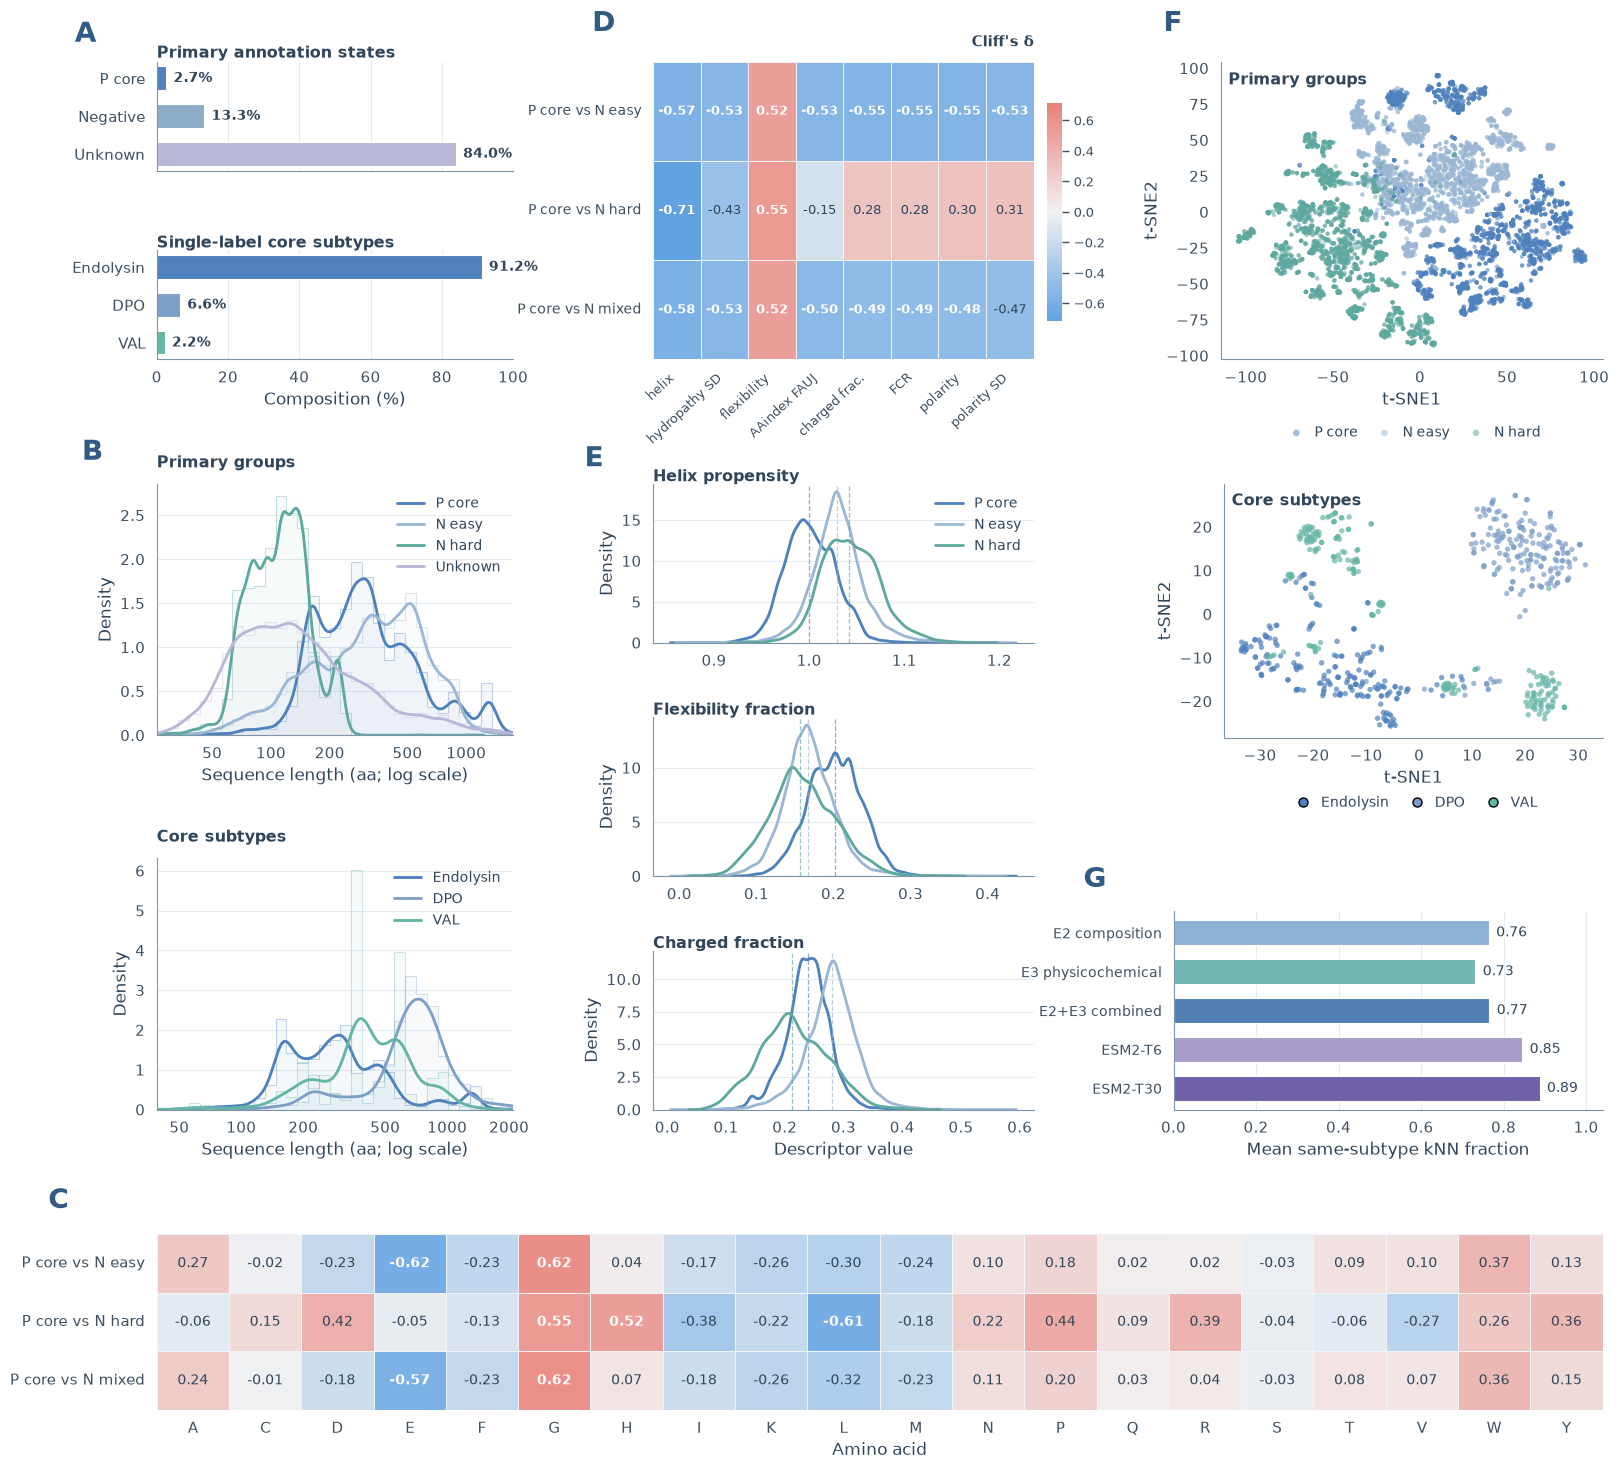

In [5]:
# ------------------------------------------------------------------
# Publication layout: A–D–F / B–E–F/G / full-width C
# ------------------------------------------------------------------
# Sized for a full-width manuscript figure; plot content and colors
# retain the source notebook's definitions.
FIG_WIDTH = 16.6
FIG_HEIGHT = 15.1

fig = plt.figure(figsize=(FIG_WIDTH, FIG_HEIGHT), facecolor="white")
outer = GridSpec(
    3, 3, figure=fig,
    width_ratios=[1.03, 1.10, 1.24],
    height_ratios=[1.00, 2.10, 0.59],
    left=0.092, right=0.963, top=0.960, bottom=0.067,
    wspace=0.36, hspace=0.34,
)

# A — two composition panels, top left
axA1, axA2 = [
    fig.add_subplot(gs)
    for gs in GridSpecFromSubplotSpec(2, 1, subplot_spec=outer[0, 0], hspace=0.73)
]
add_panel_letter(axA1, "A", x=-0.23, y=1.12)
plot_percentage_bars(axA1, primary_comp, ["P core", "Negative", "Unknown"], "Primary annotation states")
plot_percentage_bars(axA2, subtype_comp, ["Endolysin", "DPO", "VAL"], "Single-label core subtypes")
axA1.set_xlabel("")
axA1.tick_params(axis="x", labelbottom=False)

# D — physicochemical heatmap, top center
axD = fig.add_subplot(outer[0, 1])
add_panel_letter(axD, "D", x=-0.16, y=1.08)
cbar_ax = axD.inset_axes([1.035, 0.13, 0.040, 0.73])
sns.heatmap(
    desc_matrix, ax=axD, cmap=DIVERGING_CMAP,
    center=0, vmin=-HEATMAP_LIM, vmax=HEATMAP_LIM,
    linewidths=0.6, linecolor="#F0F4F8",
    annot=True, fmt=".2f", annot_kws={"fontsize": 9.7},
    cbar=True, cbar_ax=cbar_ax,
    cbar_kws={"label": ""},
)
axD.set_xlabel("")  # Avoid collision with the E panel below
axD.set_ylabel("")
axD.tick_params(axis="x", rotation=43, labelsize=9.2)
for label in axD.get_xticklabels():
    label.set_ha("right")
axD.tick_params(axis="y", rotation=0, labelsize=10.4)
cbar_ax.tick_params(labelsize=9.2)
# Use an unobstructed title above D for the common Cliff's delta scale.
# The former colorbar label collided with the adjacent F t-SNE y-axis.
cbar_ax.set_title("")
cbar_ax.set_ylabel("")
axD.set_title("Cliff's δ", loc="right", fontsize=10.8,
              fontweight="bold", pad=11)
recolor_heatmap_annotations(axD)

# F, upper panel — primary-group ESM2-T30 t-SNE
axF1 = fig.add_subplot(outer[0, 2])
add_panel_letter(axF1, "F", x=-0.15, y=1.08)
scatter_classes(
    axF1, e5_global, "TSNE1", "TSNE2", "sequence_state",
    ["P_core", "N_easy", "N_hard"], GLOBAL_PALETTE,
    s=10, alpha=0.52,
)
axF1.set_xlabel("t-SNE1")
axF1.set_ylabel("t-SNE2")
axF1.text(0.02, 0.965, "Primary groups", transform=axF1.transAxes,
          fontsize=11.8, fontweight="bold", va="top")
axF1.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.18),
            fontsize=10, markerscale=1.5, ncol=3, columnspacing=0.9,
            handletextpad=0.3)
# Fill the right-hand column instead of preserving a narrow, almost-square box.
# This also shifts the y-axis away from D's colorbar.
axF1.set_box_aspect(0.78)
axF1.set_anchor("E")

# B — length distributions, left full middle band
axB1, axB2 = [
    fig.add_subplot(gs)
    for gs in GridSpecFromSubplotSpec(2, 1, subplot_spec=outer[1, 0], hspace=0.49)
]
add_panel_letter(axB1, "B", x=-0.21, y=1.07)
plot_length_distribution(
    axB1, length_global,
    ["P_core", "N_easy", "N_hard", "Unknown"], LENGTH_GLOBAL_PALETTE,
)
plot_length_distribution(
    axB2, length_subtypes,
    ["Endolysin", "DPO", "VAL"], LENGTH_SUBTYPE_PALETTE,
)
# Subtitles must sit above the KDE density region, not over the peaks.
axB1.set_title("Primary groups", loc="left", fontsize=11.8,
               fontweight="bold", pad=12)
axB2.set_title("Core subtypes", loc="left", fontsize=11.8,
               fontweight="bold", pad=12)

# E — three physicochemical-property distributions, center middle
axesE = [
    fig.add_subplot(gs)
    for gs in GridSpecFromSubplotSpec(3, 1, subplot_spec=outer[1, 1], hspace=0.47)
]
add_panel_letter(axesE[0], "E", x=-0.18, y=1.07)
for ax, feature in zip(axesE, selected_properties):
    label = PROPERTY_LABELS.get(feature, short_descriptor(feature))
    if property_mode == "raw":
        plot_property_raw(ax, property_raw, feature, label)
    else:
        plot_property_summary(ax, property_summary, feature, label)
if property_mode == "raw":
    handles = [
        Line2D([0], [0], color=COLORS[g], lw=2, label=DISPLAY_NAMES[g])
        for g in ["P_core", "N_easy", "N_hard"]
    ]
    axesE[0].legend(handles=handles, frameon=False,
                    fontsize=10.0, loc="upper right")
    axesE[-1].set_xlabel("Descriptor value")

# F, lower panel + G bar-only, right middle band
axF2, axG = [
    fig.add_subplot(gs)
    for gs in GridSpecFromSubplotSpec(
        2, 1, subplot_spec=outer[1, 2],
        height_ratios=[1.28, 1.0], hspace=0.77,
    )
]
scatter_classes(
    axF2, e5_subtypes, "TSNE1", "TSNE2", "subtype_label",
    ["endolysin", "depolymerase", "virion_associated_lytic_enzyme"],
    SUBTYPE_PALETTE, s=15, alpha=0.70,
)
axF2.set_xlabel("t-SNE1")
axF2.set_ylabel("t-SNE2")
axF2.text(0.02, 0.965, "Core subtypes", transform=axF2.transAxes,
          fontsize=11.8, fontweight="bold", va="top")
axF2.legend(
    handles=[
        Line2D([0], [0], marker="o", color="none", markerfacecolor=COLORS["Endolysin"],
               markersize=6.5, label="Endolysin"),
        Line2D([0], [0], marker="o", color="none", markerfacecolor=COLORS["DPO"],
               markersize=6.5, label="DPO"),
        Line2D([0], [0], marker="o", color="none", markerfacecolor=COLORS["VAL"],
               markersize=6.5, label="VAL"),
    ],
    frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.18),
    fontsize=10.0, ncol=3, columnspacing=1.0,
    handletextpad=0.3,
)
# Increase the subtype plot width and align it with the right edge of F1/G.
# Only F's plotting boxes change; G and the remaining panels are untouched.
axF2.set_box_aspect(0.67)
axF2.set_anchor("E")

# G — only the same-subtype neighborhood bar chart (no silhouette curves)
add_panel_letter(axG, "G", x=-0.21, y=1.09)
bar_y = np.arange(len(rep_order))[::-1]
bar_vals = subtype_knn_rep["value"].to_numpy(dtype=float)
bar_colors = [COLORS[rep] for rep in rep_order]
axG.barh(bar_y, bar_vals, color=bar_colors, height=0.63,
         edgecolor="white", linewidth=0.8)
axG.set_yticks(bar_y)
axG.set_yticklabels(rep_order, fontsize=10.1)
axG.set_xlim(0, 1.04)
axG.set_xlabel("Mean same-subtype kNN fraction")
for yy, val in zip(bar_y, bar_vals):
    axG.text(val + 0.018, yy, f"{val:.2f}", va="center", ha="left",
             fontsize=10.0, color="#31465A")
style_axis(axG, grid=True, axis="x")

# C — complete amino-acid composition heatmap, full width at bottom
axC = fig.add_subplot(outer[2, :])
add_panel_letter(axC, "C", x=-0.075, y=1.11)
sns.heatmap(
    aac_matrix, ax=axC, cmap=DIVERGING_CMAP,
    center=0, vmin=-HEATMAP_LIM, vmax=HEATMAP_LIM,
    linewidths=0.6, linecolor="#F0F4F8",
    annot=True, fmt=".2f", annot_kws={"fontsize": 10.1},
    cbar=False,  # D displays the shared Cliff's delta scale.
)
axC.set_xlabel("Amino acid")
axC.set_ylabel("")
axC.tick_params(axis="x", rotation=0, labelsize=10.7)
axC.tick_params(axis="y", rotation=0, labelsize=10.9)
recolor_heatmap_annotations(axC)

# Export with vector paths/text and rasterized scatter points in the PDF.
PNG_PATH = OUTPUT_DIR / "phagelysdata_eda_panel_v9.png"
PDF_PATH = OUTPUT_DIR / "phagelysdata_eda_panel_v9.pdf"
fig.savefig(PNG_PATH, dpi=350, bbox_inches="tight", facecolor="white")
fig.savefig(PDF_PATH, bbox_inches="tight", facecolor="white")
print("Saved:", PNG_PATH)
print("Saved:", PDF_PATH)
plt.show()
